# LastN、DIN 与 SIM
## Goal
把概念变成可检查的输入、运算、梯度与对照。

数据类型：**真实历史 + 注意力教学变体**。本地教学参数不是生产默认值；机制实验不是原论文完整复现。

## Setup
每本首次从 Setup 起顺序运行，后面的格会复用前面的变量。之后只改一个参数，重跑对应格及下游格。不要把构造数据当作真实业务收益。

In [1]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "reclab/models.py").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from reclab.data import Dataset
from reclab.paths import ARTIFACTS, PROCESSED, read_json

plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#182b2b", "text.color": "#182b2b",
    "axes.facecolor": "white", "figure.facecolor": "white",
    "grid.color": "#d4ddda", "axes.axisbelow": True})
dataset = Dataset()
print("Project:", PROJECT)
print("Dataset version:", dataset.manifest["dataset_version"])
print("Python:", sys.executable)
assert Path(sys.executable).parent == PROJECT / ".venv/bin", "请选择 Recommendation Lab 内核"

Project: /Users/lizuolin/local/recommendation-lab
Dataset version: 2772cab0aca8cb81
Python: /Users/lizuolin/local/recommendation-lab/.venv/bin/python


## Steps
讲义对应：05_LastN_01.pdf, 05_LastN_02.pdf, 05_LastN_03.pdf

### 真实 LastN 与均值池化
使用训练截止已保存商品向量做表示诊断，不评估早期样本预测收益。

**先预测：** 逆序后均值为什么不变？改变窗口截断长度呢？

In [2]:
import torch
from reclab.learning.networks import TargetAttention
torch.manual_seed(42);torch.set_num_threads(4)
vectors=torch.tensor(np.load(ARTIFACTS/"runs/baseline-history32/item_vectors.npy"))
user=max(dataset.histories,key=lambda u:len(dataset.histories[u]))
ids=dataset.histories[user][-min(1000,len(dataset.histories[user])):]
history=vectors[ids][None,:,:];mask=torch.ones(1,len(ids),dtype=torch.bool)
assert torch.allclose(history.mean(1),history.flip(1).mean(1),atol=1e-6)
print("Real history length:",len(ids),"user:",dataset.users[user])

Real history length: 1000 user: 1150086


### DIN 风格的候选相关激活
输入 h、q、h-q、h*q。这里是 softmax 教学变体，未实现 Dice/原论文正则；随机权重不代表已学好的兴趣。

**先预测：** 同一用户的表示为什么会随候选改变？这还能缓存成独立用户塔吗？

class TargetAttention(nn.Module):
    """DIN-style candidate-dependent activation, softmax-normalized teaching variant."""

    def __init__(self, dim, hidden=16):
        super().__init__()
        self.activation = nn.Sequential(
            nn.Linear(dim * 4, hidden), nn.ReLU(), nn.Linear(hidden, 1)
        )

    def forward(self, history, candidate, mask):
        query = candidate.unsqueeze(1).expand_as(history)
        logits = self.activation(
            torch.cat([history, query, history - query, history * query], -1)
        ).squeeze(-1)
        weights = logits.masked_fill(~mask, -1e9).softmax(-1) * mask
        weights = weights / weights.sum(-1, keepdim=True).clamp_min(1e-8)
        return (history * weights.unsqueeze(-1)).sum(1), weights

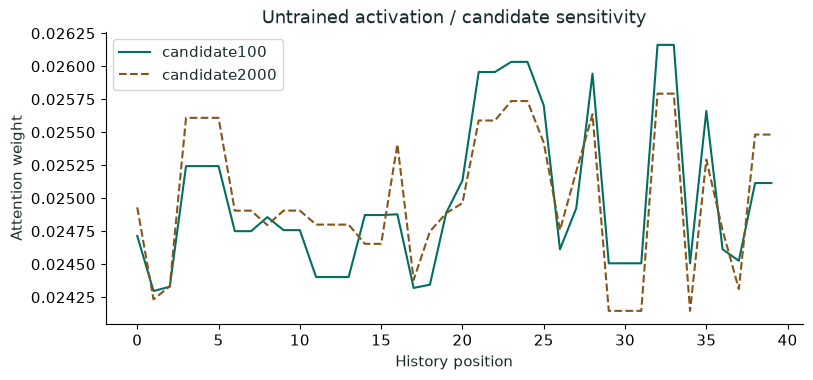

In [3]:
attention=TargetAttention(vectors.shape[1])
short=history[:,-40:];short_mask=mask[:,-40:]
qa=vectors[100][None,:];qb=vectors[2000][None,:]
pa,wa=attention(short,qa,short_mask);pb,wb=attention(short,qb,short_mask)
assert torch.allclose(wa.sum(-1),torch.ones(1))
display(Code(inspect.getsource(TargetAttention),language="python"))
plt.plot(wa[0].detach(),label="candidate100",color="#006e60")
plt.plot(wb[0].detach(),label="candidate2000",color="#855519",linestyle="--")
plt.xlabel("History position");plt.ylabel("Attention weight");plt.title("Untrained activation / candidate sensitivity");plt.legend();plt.show()

### 让激活单元真正反向传播
人为向量拟合任务，只检查可学习性，不是 CTR 标签。

**先预测：** 权重变化是否意味着真实用户更感兴趣？还缺什么证据？

In [4]:
optimizer=torch.optim.Adam(attention.parameters(),lr=.02);curve=[]
for _ in range(40):
    optimizer.zero_grad();pooled,_=attention(short,qa,short_mask)
    loss=torch.nn.functional.mse_loss(pooled,qa)
    loss.backward();optimizer.step();curve.append(float(loss.detach()))
assert curve[-1]<curve[0]
print("Artificial vector-fit loss:",curve[0],"->",curve[-1])

Artificial vector-fit loss: 0.04444105550646782 -> 0.019344493746757507


### SIM 风格的先检索后激活
从真实长历史按类目和相似度筛 TopK。展示检索/激活解耦，未复现 SIM 完整训练与论文性能。

**先预测：** K 增加时，计算量与表示误差一定单调变化吗？

In [5]:
K=20;candidate_id=100;candidate=vectors[candidate_id][None,:]
category=dataset.items[candidate_id-1]["category"]
pool=[i for i in ids if dataset.items[i-1]["category"]==category] or ids
pool_vectors=vectors[pool]
selected=torch.topk(pool_vectors@candidate[0],min(K,len(pool))).indices
filtered=pool_vectors[selected][None,:,:]
with torch.no_grad():
    full,_=attention(history,candidate,mask)
    reduced,_=attention(filtered,candidate,torch.ones(1,filtered.shape[1],dtype=torch.bool))
print("Full/filtered tokens:",len(ids),filtered.shape[1])
print("Representation distance (not accuracy):",float(torch.norm(full-reduced)))
assert filtered.shape[1]<=K

Full/filtered tokens: 1000 1
Representation distance (not accuracy): 1.0099929571151733


## Checks
所有断言和输出都可回溯到代码。它们验证算子、数据快照或机制，不是线上收益。

## Next Steps
先记录预测，只改一个变量，再运行对应实验格。需要查看辅助函数时，打开 reclab/learning/。